# The link-layer playground

What might ride on the modem: the experiments of `tools/toystack.py` (docs/PLAN.md, S8).
Its frame format and protocols are drafts for experiments, not decisions; this notebook is
about what the 110 waveform's behaviour means for any protocol built on it.

It is generated from `docs/playground.py` (`python tools/build_notebook.py playground`), and
the test suite runs that script.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from nbtools import QUICK

from m110c.spec import mode
from m110c.spec import tables as T
from m110c.tx import transmit_bytes

plt.rcParams["figure.figsize"] = (8, 3.5)

## 1. Every transmission has a fixed cost

A transmission is a preamble (0.6 s with zero or short interleave, 4.8 s with long), the
data, then the end-of-message marker and the flush, padded to the end of an interleaver
block. However small the message, that much is sent. So the fraction of the air time that
carries the message grows with its size, and much more slowly with long interleave: a
200-byte message at 1200L spends most of its 9.6 s on overhead. This is why a protocol
over 110 batches its frames, piggybacks its acknowledgements, and keeps long interleave
for long messages. The sawtooth is the padding: a transmission always ends on a whole
interleaver block, so a message just over a block boundary pays for nearly a whole block.

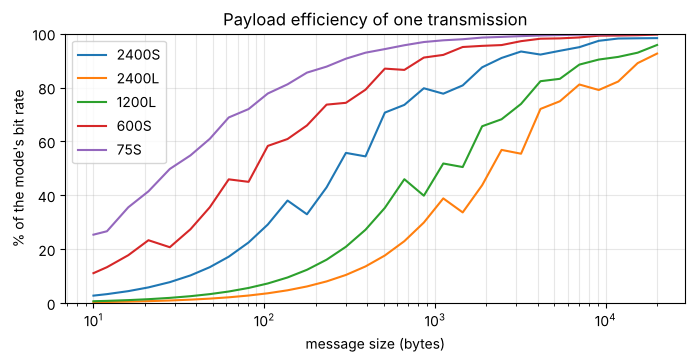

In [2]:
sizes = np.unique(np.geomspace(10, 20_000, 12 if QUICK else 30).astype(int))
for rate, interleave in (
    (2400, "short"),
    (2400, "long"),
    (1200, "long"),
    (600, "short"),
    (75, "short"),
):
    m = mode(rate, interleave)
    seconds = np.array([transmit_bytes(bytes(n), m).size / T.SYMBOL_RATE for n in sizes])
    efficiency = 8 * sizes / seconds / rate
    plt.semilogx(sizes, 100 * efficiency, label=str(m))
plt.xlabel("message size (bytes)")
plt.ylabel("% of the mode's bit rate")
plt.title("Payload efficiency of one transmission")
plt.ylim(0, 100)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()